In [ ]:
#Ella — Camera test

def start_camera():
    js = Javascript("""
    async function startCamera() {
        const video = document.createElement('video');
        video.style.width = '480px';
        video.style.height = '360px';
        video.autoplay = true;
        video.playsInline = true;

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        document.body.appendChild(video);

        return new Promise((resolve) => {
            video.onplaying = () => {
                const canvas = document.createElement('canvas');
                canvas.width = video.videoWidth;
                canvas.height = video.videoHeight;

                const context = canvas.getContext('2d');

                resolve({
                    video: video,
                    canvas: canvas,
                    context: context
                });
            };
        });
    }

    startCamera();
    """)
    display(js)

<IPython.core.display.Javascript object>

Frame captured successfully!
Frame dimensions: (480, 640, 3)


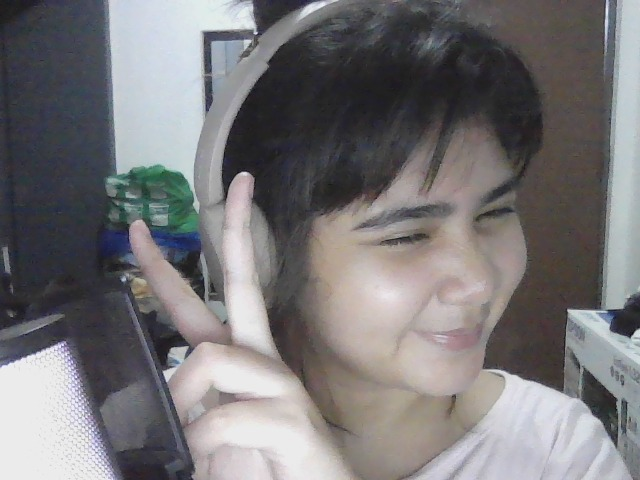

In [ ]:
#Ella — Capture a webcam frame

from google.colab.output import eval_js
from base64 import b64decode
from IPython.display import display, Javascript
import numpy as np
import cv2

def capture_frame():
    js = Javascript("""
    async function captureFrame() {
        const div = document.createElement('div');
        const video = document.createElement('video');
        const button = document.createElement('button');

        button.textContent = 'Capture Frame';
        video.style.display = 'block';
        video.style.width = '480px';
        video.autoplay = true;
        video.playsInline = true;

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        div.appendChild(video);
        div.appendChild(button);
        document.body.appendChild(div);

        await new Promise(resolve => {
            button.onclick = resolve;
        });

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(
            video, 0, 0, canvas.width, canvas.height
        );

        stream.getTracks().forEach(track => track.stop());
        div.remove();

        return canvas.toDataURL('image/jpeg');
    }
    """)
    display(js)
    data = eval_js("captureFrame()")
    image_bytes = b64decode(data.split(',')[1])
    image_array = np.frombuffer(image_bytes, dtype=np.uint8)
    frame = cv2.imdecode(image_array, cv2.IMREAD_COLOR)
    return frame

frame = capture_frame()

if frame is not None:
    print("Frame captured successfully!")
    print("Frame dimensions:", frame.shape)
    display_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    from PIL import Image
    display(Image.fromarray(display_frame))

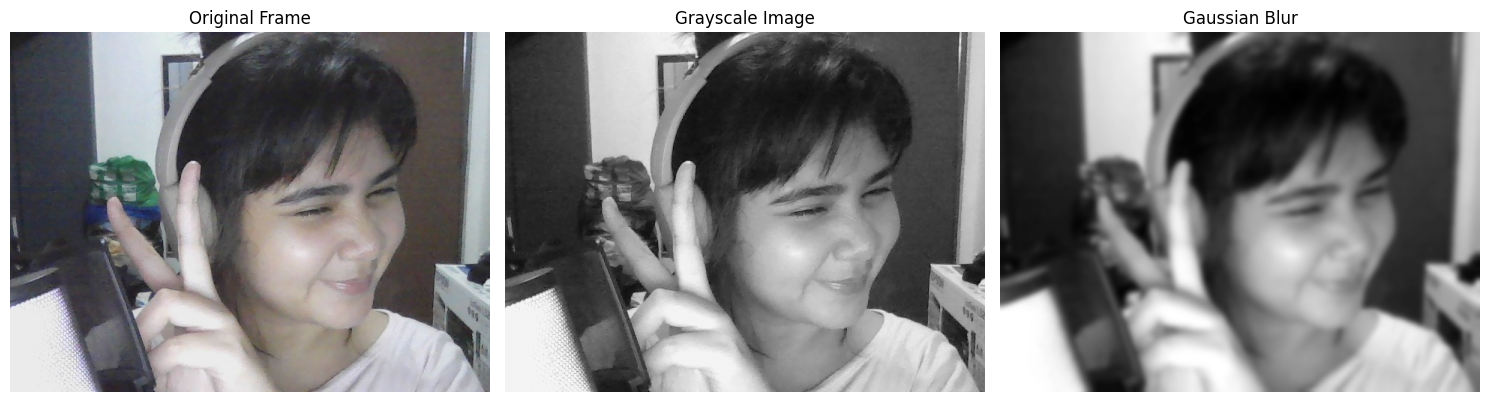

In [ ]:
#Ella — Image Processing

import matplotlib.pyplot as plt

if frame is None:
    raise RuntimeError("No webcam frame is available. Run the camera capture cell again and allow camera access.")

gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

blurred_frame = cv2.GaussianBlur(gray_frame, (21, 21), 0)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray_frame, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(blurred_frame, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

<IPython.core.display.Javascript object>

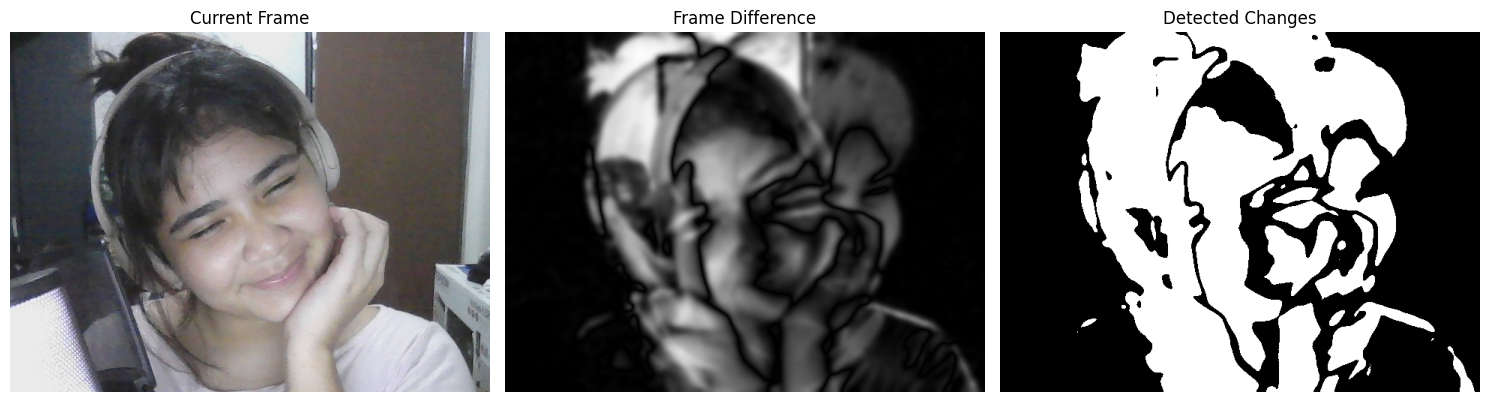

In [ ]:
#Ella — Motion Detection

new_frame = capture_frame()

if frame is None:
    raise RuntimeError("The first webcam frame is missing. Run the camera capture cell again.")
if new_frame is None:
    raise RuntimeError("The second webcam frame was not captured. Try the capture cell again and allow camera access.")

previous_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
current_gray = cv2.cvtColor(new_frame, cv2.COLOR_BGR2GRAY)

previous_blur = cv2.GaussianBlur(previous_gray, (21, 21), 0)
current_blur = cv2.GaussianBlur(current_gray, (21, 21), 0)

frame_diff = cv2.absdiff(previous_blur, current_blur)

_, threshold = cv2.threshold(
    frame_diff, 25, 255, cv2.THRESH_BINARY
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(new_frame, cv2.COLOR_BGR2RGB))
plt.title("Current Frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(frame_diff, cmap="gray")
plt.title("Frame Difference")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(threshold, cmap="gray")
plt.title("Detected Changes")
plt.axis("off")

plt.tight_layout()
plt.show()

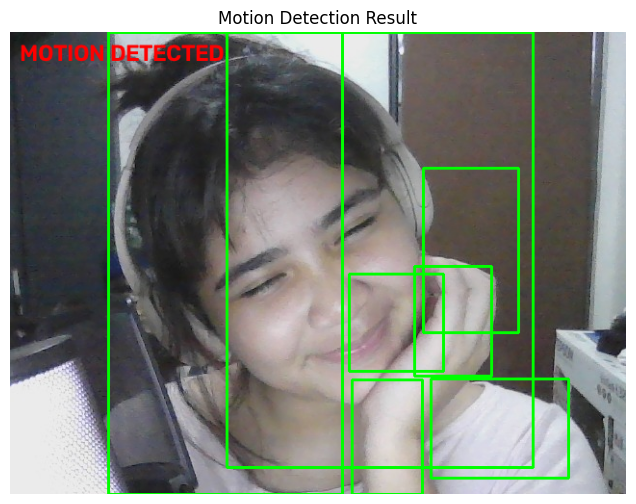

Status: MOTION DETECTED
Contours found: 26


In [ ]:
#Ella — Detect moving areas

contours, _ = cv2.findContours(
    threshold.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

motion_frame = new_frame.copy()

MIN_AREA = 1500

motion_detected = False

for contour in contours:
    area = cv2.contourArea(contour)

    if area < MIN_AREA:
        continue

    motion_detected = True

    x, y, w, h = cv2.boundingRect(contour)

    cv2.rectangle(
        motion_frame,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

if motion_detected:
    status = "MOTION DETECTED"
else:
    status = "NO MOTION"

cv2.putText(
    motion_frame,
    status,
    (10, 30),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 255) if motion_detected else (0, 255, 0),
    2
)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(motion_frame, cv2.COLOR_BGR2RGB))
plt.title("Motion Detection Result")
plt.axis("off")
plt.show()

print("Status:", status)
print("Contours found:", len(contours))

In [ ]:
# Shayna — Imports & Security Setup

import os
import csv
import cv2
import html
import time
import pandas as pd
import ipywidgets as widgets

from datetime import datetime
from IPython.display import display, HTML, clear_output, Image
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image as PILImage

SNAPSHOT_DIR = "security_snapshots"
EVENT_LOG = "security_event_log.csv"

os.makedirs(SNAPSHOT_DIR, exist_ok=True)

if not os.path.exists(EVENT_LOG):
    with open(EVENT_LOG, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["Timestamp", "Event", "Snapshot"])

latest_processed_frame = None
latest_motion_status = "WAITING FOR CAMERA"

print("MDSMS imports and security storage initialized!")

MDSMS imports and security storage initialized!


In [ ]:

# Shayna — Security Event Logging

def record_security_event(frame, event_type="MOTION DETECTED"):
    """Save a snapshot and record a security event."""

    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    filename = ""

    if frame is not None:
        safe_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
        filename = f"motion_{safe_timestamp}.jpg"
        filepath = os.path.join(SNAPSHOT_DIR, filename)

        saved = cv2.imwrite(filepath, frame)

        if not saved:
            raise IOError(f"Could not save snapshot: {filepath}")

    with open(EVENT_LOG, "a", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow([timestamp, event_type, filename])

    print(f"[{timestamp}] {event_type}")

    if filename:
        print(f"Snapshot saved: {filename}")

    return timestamp, filename


print("MDSMS security event logging is ready!")

SUWE security event logging is ready!


<IPython.core.display.Javascript object>

Camera started. Move your hand to test motion detection.
Click 'Stop Motion Detection' under the camera to stop.
[2026-10-11 12:57:33] MOTION DETECTED
Snapshot saved: motion_20261011_125733_847311.jpg


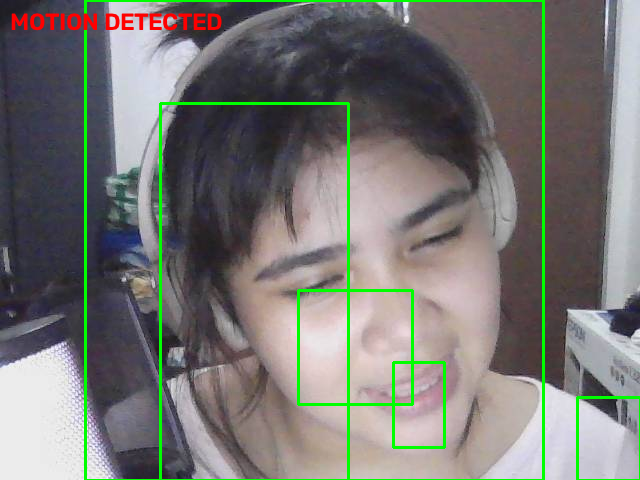

[2026-10-11 12:57:43] MOTION DETECTED
Snapshot saved: motion_20261011_125743_912230.jpg
[2026-10-11 12:57:47] MOTION DETECTED
Snapshot saved: motion_20261011_125747_254719.jpg
[2026-10-11 12:57:50] MOTION DETECTED
Snapshot saved: motion_20261011_125750_559527.jpg
Motion detection has ended.


In [ ]:

# Ella + Shayna — Live Motion Detection

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image as PILImage
import numpy as np
import cv2
import time

display(Javascript("""
window.motionStop = false;
window.motionStream = null;
window.motionVideo = null;

window.startMotionCamera = async function() {
    const oldContainer =
        document.getElementById('motion-camera-container');
    if (oldContainer) oldContainer.remove();

    const container = document.createElement('div');
    container.id = 'motion-camera-container';

    const video = document.createElement('video');
    video.style.width = '320px';
    video.autoplay = true;
    video.playsInline = true;
    video.muted = true;

    const stopButton = document.createElement('button');
    stopButton.textContent = 'Stop Motion Detection';
    stopButton.style.display = 'block';
    stopButton.style.margin = '10px 0';
    stopButton.style.padding = '10px';

    container.appendChild(video);
    container.appendChild(stopButton);
    document.body.appendChild(container);

    window.motionStream =
        await navigator.mediaDevices.getUserMedia({
            video: { width: 640, height: 480 }
        });

    window.motionVideo = video;
    video.srcObject = window.motionStream;
    await video.play();

    window.motionStop = false;

    stopButton.onclick = function() {
        window.motionStop = true;
        window.motionStream.getTracks().forEach(
            track => track.stop()
        );
        stopButton.textContent = 'Stopping...';
    };

    return true;
};

window.getMotionFrame = function() {
    if (window.motionStop) return null;

    const video = window.motionVideo;
    if (!video || video.readyState < 2) return null;

    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;

    canvas.getContext('2d').drawImage(
        video, 0, 0, canvas.width, canvas.height
    );

    return canvas.toDataURL('image/jpeg', 0.7);
};

window.isMotionStopped = function() {
    return window.motionStop;
};
"""))

eval_js("startMotionCamera()")

print("Camera started. Move your hand to test motion detection.")
print("Click 'Stop Motion Detection' under the camera to stop.")

previous_gray = None
MIN_AREA = 1500
display_handle = None

# Avoid logging every frame during continuous movement.
motion_was_active = False

latest_processed_frame = None
latest_motion_status = "WAITING FOR CAMERA"

try:
    while not eval_js("isMotionStopped()"):

        data = eval_js("getMotionFrame()")

        if data is None:
            time.sleep(0.05)
            continue

        image_bytes = b64decode(data.split(",")[1])
        image_array = np.frombuffer(
            image_bytes, dtype=np.uint8
        )

        frame = cv2.imdecode(
            image_array, cv2.IMREAD_COLOR
        )

        if frame is None:
            continue

        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray = cv2.GaussianBlur(gray, (21, 21), 0)

        if previous_gray is None:
            previous_gray = gray
            continue

        frame_diff = cv2.absdiff(previous_gray, gray)

        _, threshold = cv2.threshold(
            frame_diff, 25, 255, cv2.THRESH_BINARY
        )

        threshold = cv2.dilate(
            threshold, None, iterations=2
        )

        contours, _ = cv2.findContours(
            threshold,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        motion_detected = False

        for contour in contours:
            if cv2.contourArea(contour) < MIN_AREA:
                continue

            motion_detected = True

            x, y, w, h = cv2.boundingRect(contour)

            cv2.rectangle(
                frame,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

        status = (
            "MOTION DETECTED"
            if motion_detected
            else "NO MOTION"
        )

        color = (
            (0, 0, 255)
            if motion_detected
            else (0, 255, 0)
        )

        cv2.putText(
            frame,
            status,
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            color,
            2
        )

        # Share the latest processed result with SUWE.
        latest_processed_frame = frame.copy()
        latest_motion_status = status

        # Log once when motion begins.
        if motion_detected and not motion_was_active:
            try:
                record_security_event(
                    frame=frame,
                    event_type="MOTION DETECTED"
                )
            except Exception as log_error:
                print("Security logging error:", log_error)

        motion_was_active = motion_detected

        rgb_frame = cv2.cvtColor(
            frame, cv2.COLOR_BGR2RGB
        )

        output_image = PILImage.fromarray(rgb_frame)

        if display_handle is None:
            display_handle = display(
                output_image, display_id=True
            )
        else:
            display_handle.update(output_image)

        previous_gray = gray
        time.sleep(0.05)

except Exception as error:
    print("Motion detection stopped because:", error)

finally:
    try:
        eval_js("""
        if (window.motionStream) {
            window.motionStream.getTracks().forEach(
                track => track.stop()
            );
        }
        if (window.motionVideo) {
            window.motionVideo.srcObject = null;
        }
        """)
    except Exception:
        pass

    print("Motion detection has ended.")

In [ ]:
# Shayna — MDSMS Welcome Screen + Side-By-Side Dashboard

import os
import csv
import html
import base64
import pandas as pd
import cv2
import ipywidgets as widgets

from IPython.display import display, HTML, clear_output


# 1. MDSMS DESIGN SYSTEM

MDSMS_STYLE = """
<style>
@import url('https://fonts.googleapis.com/css2?family=Bodoni+Moda:ital,wght@0,600;0,700;1,700&display=swap');

.MDSMS-shell {
    width: 100%;
    max-width: 900px;
    margin: 12px auto;
    box-sizing: border-box;
    color: #FFF0FA;
    font-family: Consolas, 'Courier New', monospace;
}

.MDSMS-shell * { box-sizing: border-box; }

/* WELCOME SCREEN */
.MDSMS-home {
    position: relative;
    height: 440px;
    overflow: hidden;
    display: flex;
    flex-direction: column;
    align-items: center;
    justify-content: center;
    text-align: center;
    padding: 24px;
    border: 1px solid #985477;
    background: radial-gradient(
        ellipse at 50% 70%,
        #663052 0%, #30172C 48%, #140D18 100%
    );
}

.MDSMS-home::before {
    content: "";
    position: absolute;
    left: -15%;
    right: -15%;
    bottom: -95px;
    height: 235px;
    background-image:
        linear-gradient(#FF83C855 1px, transparent 1px),
        linear-gradient(90deg, #FF83C855 1px, transparent 1px);
    background-size: 30px 25px;
    transform: perspective(200px) rotateX(52deg);
    animation: MDSMS-grid 3s linear infinite;
    mask-image: linear-gradient(transparent, black 25%, transparent);
    pointer-events: none;
}

@keyframes MDSMS-grid {
    from { background-position: 0 0; }
    to { background-position: 0 25px; }
}

.MDSMS-eyebrow {
    position: relative;
    color: #FFB5DC;
    font-size: 9px;
    letter-spacing: 3px;
}

.MDSMS-title {
    position: relative;
    margin: 12px 0;
    color: #FFF0FA;
    font: italic 700 clamp(55px, 9vw, 78px)/1.1
        'Bodoni Moda', Didot, serif;
    text-shadow: 0 0 10px #FFB5DC, 0 0 28px #FF50B8;
}

.MDSMS-tagline {
    position: relative;
    color: #F5B5D8;
    font-size: 9px;
    letter-spacing: 2px;
    line-height: 2;
}

.MDSMS-home-footer {
    position: absolute;
    bottom: 15px;
    color: #D39ABF;
    font-size: 8px;
    letter-spacing: 2px;
}

/* DASHBOARD */
.MDSMS-dashboard {
    border: 1px solid #985477;
    background:
        linear-gradient(#FF78C908 1px, transparent 1px),
        linear-gradient(90deg, #FF78C908 1px, transparent 1px),
        #140D18;
    background-size: 22px 22px;
    padding: 18px;
}

.MDSMS-header {
    display: flex;
    align-items: center;
    flex-wrap: wrap;
    gap: 12px;
    border-bottom: 1px solid #63304F;
    padding-bottom: 14px;
}

.MDSMS-brand {
    color: #FFF0FA;
    font: italic 700 32px 'Bodoni Moda', Didot, serif;
    text-shadow: 0 0 12px #FF78C5;
}

.MDSMS-sub {
    color: #DDA6C8;
    font-size: 9px;
    letter-spacing: 1.5px;
    line-height: 1.8;
}

.MDSMS-status {
    margin-left: auto;
    border: 1px solid #985477;
    padding: 7px 9px;
    color: #FFC5E4;
    background: #281326;
    font-size: 8px;
}

.MDSMS-section-title {
    margin: 18px 0 10px;
    color: #FF9DD3;
    font-size: 10px;
    letter-spacing: 2px;
}

.MDSMS-stats {
    display: grid;
    grid-template-columns: repeat(3, minmax(0, 1fr));
    gap: 9px;
}

.MDSMS-stat {
    min-width: 0;
    padding: 12px;
    border: 1px solid #75405E;
    background: #281626;
}

.MDSMS-stat-label {
    color: #F2B8D9;
    font-size: 8px;
    letter-spacing: 1px;
}

.MDSMS-stat-value {
    margin-top: 7px;
    color: #FFF0FA;
    font-size: 25px;
    overflow-wrap: anywhere;
    text-shadow: 0 0 10px #FF50B8;
}

/* TWO-COLUMN MONITOR AREA */
.MDSMS-monitor-grid {
    display: grid;
    grid-template-columns: minmax(0, 1fr) minmax(0, 1fr);
    gap: 12px;
    align-items: stretch;
}

.MDSMS-monitor-panel {
    min-width: 0;
    padding: 12px;
    border: 1px solid #75405E;
    background: #1B101E;
}

.MDSMS-monitor-panel .MDSMS-section-title {
    margin-top: 0;
}

.MDSMS-status-panel {
    margin-top: 10px;
    padding: 12px;
    border: 1px solid #75405E;
    background: #211321;
}

.MDSMS-status-value {
    margin-top: 6px;
    color: #FFB5DC;
    font-size: 11px;
}

/* PROCESSED CAMERA FRAME */
.MDSMS-processed {
    margin-top: 10px;
    padding: 10px;
    border: 1px solid #75405E;
    background: #1B101E;
}

.MDSMS-processed img {
    display: block;
    width: 100%;
    max-width: 420px;
    height: auto;
    margin-top: 8px;
    border: 1px solid #985477;
}

/* SECURITY EVENT HISTORY — VISIBLE PINK SCROLLBAR */
.MDSMS-table-wrap {
    width: 100%;
    max-height: 230px;
    overflow: auto;
    border: 1px solid #985477;
    background: #1B101E;
    scrollbar-color: #FF83C8 #281326;
    scrollbar-width: auto;
}

.MDSMS-table-wrap::-webkit-scrollbar {
    width: 12px;
    height: 12px;
}

.MDSMS-table-wrap::-webkit-scrollbar-track {
    background: #281326;
    border-left: 1px solid #63304F;
}

.MDSMS-table-wrap::-webkit-scrollbar-thumb {
    background: #FF83C8;
    border: 2px solid #281326;
    border-radius: 6px;
}

.MDSMS-table-wrap::-webkit-scrollbar-thumb:hover {
    background: #FFB5DC;
}

.MDSMS-table {
    width: 100%;
    border-collapse: collapse;
    font-size: 9px;
    text-align: left;
}

.MDSMS-table th {
    position: sticky;
    top: 0;
    z-index: 1;
    background: #35182F;
    color: #FFB5DC;
    letter-spacing: 1px;
    padding: 11px 8px;
    border-bottom: 1px solid #985477;
}

.MDSMS-table td {
    color: #F7D7E9;
    padding: 10px 8px;
    border-bottom: 1px solid #48233B;
    overflow-wrap: anywhere;
}

.MDSMS-empty {
    padding: 18px;
    color: #E8B8D4;
    border: 1px dashed #75405E;
    background: #1B101E;
    font-size: 10px;
}

/* ROOMIER IMAGE ARCHIVE — PINK SCROLLBAR */
.MDSMS-archive {
    height: 390px;
    max-height: 390px;
    overflow-y: auto;
    overflow-x: hidden;
    padding: 12px;
    border: 1px solid #985477;
    background: #140D18;
    scrollbar-color: #FF83C8 #281626;
    scrollbar-width: auto;
}

.MDSMS-archive::-webkit-scrollbar {
    width: 12px;
}

.MDSMS-archive::-webkit-scrollbar-track {
    background: #281326;
    border-left: 1px solid #63304F;
}

.MDSMS-archive::-webkit-scrollbar-thumb {
    background: #FF83C8;
    border: 2px solid #281326;
    border-radius: 6px;
}

.MDSMS-archive::-webkit-scrollbar-thumb:hover {
    background: #FFB5DC;
}

.MDSMS-snapshot {
    padding: 10px 0;
    margin-bottom: 10px;
    border-bottom: 1px solid #48233B;
}

.MDSMS-snapshot-name {
    color: #FFB5DC;
    font-size: 9px;
    margin-bottom: 8px;
    overflow-wrap: anywhere;
}

.MDSMS-snapshot img {
    display: block;
    width: 100%;
    max-width: 320px;
    height: auto;
    border: 1px solid #985477;
}

.MDSMS-footer {
    padding-top: 14px;
    margin-top: 18px;
    border-top: 1px solid #63304F;
    color: #C18AAA;
    text-align: center;
    font-size: 8px;
    letter-spacing: 2px;
}

/* RESPONSIVE LAYOUT */
@media (max-width: 600px) {
    .MDSMS-dashboard { padding: 11px; }
    .MDSMS-stats { grid-template-columns: 1fr; }
    .MDSMS-status { margin-left: 0; }
    .MDSMS-home { height: 400px; }
    .MDSMS-table { font-size: 8px; }
    .MDSMS-monitor-grid {
        grid-template-columns: minmax(0, 1fr);
    }
}

/* LIGHT-PINK BUTTON TEXT */
.MDSMS-hot-pink,
.MDSMS-hot-pink button,
.MDSMS-hot-pink .widget-button,
.MDSMS-hot-pink button *,
.MDSMS-hot-pink .widget-button * {
    color: #FFB5DC !important;
    -webkit-text-fill-color: #FFB5DC !important;
}
</style>
"""


# 2. NAVIGATION BUTTONS

MDSMS_output = widgets.Output(
    layout=widgets.Layout(width="100%")
)

enter_button = widgets.Button(
    description="ENTER CONSOLE  ➜",
    layout=widgets.Layout(width="190px", height="40px")
)

home_button = widgets.Button(
    description="✦  HOME",
    layout=widgets.Layout(width="120px", height="36px")
)

refresh_button = widgets.Button(
    description="↻  REFRESH DATA",
    layout=widgets.Layout(width="160px", height="36px")
)

for button in (enter_button, home_button, refresh_button):
    button.style.button_color = "#52223F"
    button.style.font_weight = "bold"
    button.style.text_color = "#FFB5DC"
    button.add_class("MDSMS-hot-pink")


# 3. WELCOME SCREEN

def show_MDSMS_home(button=None):
    with MDSMS_output:
        clear_output(wait=True)

        display(HTML(MDSMS_STYLE + """
        <div class="MDSMS-shell">
          <div class="MDSMS-home">
            <div class="MDSMS-eyebrow">
              ✦ &nbsp; SYSTEM INITIALIZED &nbsp; ✦
            </div>
            <div class="MDSMS-title">Welcome</div>
            <div class="MDSMS-tagline">
              <span style="font:italic 700 25px 'Bodoni Moda',Didot,serif;
              color:#FFB5DC;">MDSMS</span>
              <br>
              MOTION DETECTION SECURITY SYSTEM
            </div>
            <div style="position:relative;color:#FF91CF;
            font-size:22px;margin-top:16px;">
              ✦ &nbsp; ✧ &nbsp; ✦
            </div>
            <div class="MDSMS-home-footer">
              CSC 126 / COMPUTER VISION PROJECT
            </div>
          </div>
        </div>
        """))

        display(widgets.HBox(
            [enter_button],
            layout=widgets.Layout(
                width="100%",
                justify_content="center",
                padding="12px",
                background_color="#281326"
            )
        ))


# 4. DASHBOARD — LOAD REAL SECURITY DATA

def show_MDSMS_dashboard(button=None):
    with MDSMS_output:
        clear_output(wait=True)

        columns = ["Timestamp", "Event", "Snapshot"]

        try:
            if os.path.exists(EVENT_LOG):
                history = pd.read_csv(EVENT_LOG)
            else:
                history = pd.DataFrame(columns=columns)

            for column in columns:
                if column not in history.columns:
                    history[column] = ""

            history = history[columns]

        except (OSError, pd.errors.EmptyDataError):
            history = pd.DataFrame(columns=columns)

        snapshots = sorted(
            [
                name for name in os.listdir(SNAPSHOT_DIR)
                if name.lower().endswith((".jpg", ".jpeg", ".png"))
            ],
            reverse=True
        ) if os.path.isdir(SNAPSHOT_DIR) else []

        motion_count = history["Event"].astype(str).str.contains(
            "MOTION DETECTED",
            case=False,
            regex=False
        ).sum()

        current_status = globals().get(
            "latest_motion_status", "WAITING FOR CAMERA"
        )

        current_frame = globals().get(
            "latest_processed_frame", None
        )

        storage_ready = (
            os.path.isdir(SNAPSHOT_DIR)
            and os.path.isfile(EVENT_LOG)
        )

        storage_status = (
            "STORAGE READY" if storage_ready
            else "STORAGE OFFLINE"
        )

        # EVENT HISTORY TABLE
        if history.empty:
            table_content = """
            <div class="MDSMS-empty">NO SECURITY EVENTS RECORDED</div>
            """
        else:
            table_rows = ""

            for _, record in history.tail(100).iloc[::-1].iterrows():
                cells = [
                    html.escape(str(record[column]))
                    for column in columns
                ]

                table_rows += "<tr>" + "".join(
                    f"<td>{value if value else '—'}</td>"
                    for value in cells
                ) + "</tr>"

            table_content = f"""
            <div class="MDSMS-table-wrap">
              <table class="MDSMS-table">
                <thead>
                  <tr>
                    <th>TIMESTAMP</th>
                    <th>EVENT</th>
                    <th>SNAPSHOT</th>
                  </tr>
                </thead>
                <tbody>{table_rows}</tbody>
              </table>
            </div>
            """

        # IMAGE ARCHIVE
        archive_items = ""

        for filename in snapshots:
            filepath = os.path.join(SNAPSHOT_DIR, filename)

            try:
                with open(filepath, "rb") as image_file:
                    image_data = base64.b64encode(
                        image_file.read()
                    ).decode("ascii")

                extension = os.path.splitext(filename)[1].lower()
                mime_type = (
                    "image/png" if extension == ".png"
                    else "image/jpeg"
                )

                archive_items += f"""
                <div class="MDSMS-snapshot">
                  <div class="MDSMS-snapshot-name">
                    {html.escape(filename)}
                  </div>
                  <img src="data:{mime_type};base64,{image_data}"
                       alt="Security snapshot">
                </div>
                """

            except (OSError, ValueError) as error:
                archive_items += f"""
                <div class="MDSMS-snapshot-name">
                  Could not load {html.escape(filename)}:
                  {html.escape(str(error))}
                </div>
                """

        if not archive_items:
            archive_items = """
            <div class="MDSMS-empty">NO SNAPSHOTS AVAILABLE</div>
            """

        # LATEST PROCESSED FRAME
        processed_html = ""

        if current_frame is not None:
            success, encoded_frame = cv2.imencode(
                ".jpg", current_frame
            )

            if success:
                encoded_data = base64.b64encode(
                    encoded_frame.tobytes()
                ).decode("ascii")

                processed_html = f"""
                <div class="MDSMS-processed">
                  <div class="MDSMS-sub">LATEST PROCESSED FRAME</div>
                  <img src="data:image/jpeg;base64,{encoded_data}"
                       alt="Latest processed frame">
                  <div class="MDSMS-status-value">
                    {html.escape(str(current_status))}
                  </div>
                </div>
                """
        else:
            processed_html = """
            <div class="MDSMS-empty">NO PROCESSED FRAME AVAILABLE</div>
            """

        # COMPLETE CENTERED DASHBOARD
        display(HTML(MDSMS_STYLE + f"""
        <div class="MDSMS-shell">
          <div class="MDSMS-dashboard">

            <div class="MDSMS-header">
              <div>
                <div class="MDSMS-brand">MDSMS</div>
                <div class="MDSMS-sub">
                  MOTION DETECTION / SECURITY CONSOLE
                </div>
              </div>
              <div class="MDSMS-status">● {storage_status}</div>
            </div>

            <div class="MDSMS-section-title">// SYSTEM TELEMETRY</div>

            <div class="MDSMS-stats">
              <div class="MDSMS-stat">
                <div class="MDSMS-stat-label">MOTION EVENTS</div>
                <div class="MDSMS-stat-value">{motion_count}</div>
              </div>
              <div class="MDSMS-stat">
                <div class="MDSMS-stat-label">SAVED SNAPSHOTS</div>
                <div class="MDSMS-stat-value">{len(snapshots)}</div>
              </div>
              <div class="MDSMS-stat">
                <div class="MDSMS-stat-label">LOG ENTRIES</div>
                <div class="MDSMS-stat-value">{len(history)}</div>
              </div>
            </div>

            <div class="MDSMS-section-title">
              // SURVEILLANCE CHANNELS
            </div>

            <!-- CAMERA LEFT, ARCHIVE RIGHT -->
            <div class="MDSMS-monitor-grid">

              <div class="MDSMS-monitor-panel">
                <div class="MDSMS-section-title">// CAMERA STATUS</div>

                <div class="MDSMS-status-panel">
                  <div class="MDSMS-sub">LATEST DETECTION</div>
                  <div class="MDSMS-status-value">
                    {html.escape(str(current_status))}
                  </div>
                </div>

                {processed_html}
              </div>

              <div class="MDSMS-monitor-panel">
                <div class="MDSMS-section-title">
                  // CAPTURED IMAGE ARCHIVE
                </div>

                <div class="MDSMS-sub" style="margin-bottom:8px;">
                  {len(snapshots)} IMAGE(S) / SCROLL TO BROWSE
                </div>

                <div class="MDSMS-archive">
                  {archive_items}
                </div>
              </div>

            </div>

            <div class="MDSMS-section-title">
              // SECURITY EVENT HISTORY
            </div>

            {table_content}

            <div class="MDSMS-footer">
              MDSMS / CSC 126 / COMPUTER VISION PROJECT
            </div>

          </div>
        </div>
        """))

        # NAVIGATION BUTTONS
        display(widgets.HBox(
            [home_button, refresh_button],
            layout=widgets.Layout(
                width="100%",
                justify_content="center",
                align_items="center",
                flex_flow="row wrap",
                gap="10px",
                padding="12px"
            )
        ))


# 5. CONNECT NAVIGATION AND DISPLAY HOME SCREEN

enter_button.on_click(show_MDSMS_dashboard)
home_button.on_click(show_MDSMS_home)
refresh_button.on_click(show_MDSMS_dashboard)

display(MDSMS_output)
show_MDSMS_home()

print("MDSMS interface ready.")

Output(layout=Layout(width='100%'))

MDSMS interface ready.
